<h1 style="text-align: center; font-size: 40px;">
**Iris Flowering Plant k-means Clustering Analysis**
</h1>

<div align="center">
    <img src="iris.png" width="400">
</div>

**Introduction: Iris Dataset and K-Means Clustering**

The Iris dataset is a widely used dataset in machine learning that contains 150 flower samples belonging to three species: Iris Setosa, Iris Versicolor, and Iris Virginica, with 50 samples from each species. Although all three belong to the Iris genus, they differ in their physical characteristics. Setosa typically has smaller petals, Versicolor has medium-sized petals, and Virginica generally has larger petals. 

The dataset contains four numerical features measured in centimeters: sepal length, sepal width, petal length, and petal width. 

The objective of this project is to apply K-Means Clustering, an unsupervised machine learning algorithm, to identify natural groupings of flowers based on these measurements without using their known species labels. The analysis will involve data preprocessing, feature scaling, determining the optimal number of clusters using the Elbow Method and Silhouette Score, and evaluating clustering performance using metrics such as the Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index. Finally, the resulting clusters will be compared with the actual species labels to assess how effectively K-Means identifies the underlying patterns in the dataset.

In [11]:
#Load Libraries
import sklearn as sk
import pandas as pd
import numpy as np

#Load iris data
from sklearn.datasets import load_iris

In [13]:
iris_data = load_iris(as_frame=True)
iris_df = iris_data.frame 

In [62]:
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [15]:
iris_df['target'].value_counts()

target
0    50
1    50
2    50
Name: count, dtype: int64

In [16]:
iris_clust_df=iris_df[['sepal length (cm)','sepal width (cm)'	,'petal length (cm)','petal width (cm)']]

In [17]:
iris_clust_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**Python Data Quality Checks**

**Check data for any Missing values ["Completeness", "Consistancy", "Accuracy"]**

What each check tells you:
- info() → Data types, columns, and non-null counts.
- isnull().sum() → Missing values per column.
- duplicated().sum() → Number of duplicate rows.
- describe() → Mean, standard deviation, minimum, maximum, and quartiles.
- shape → Number of rows and columns.
- dtypes → Data types.
- <= 0 → Potentially invalid measurements.
- value_counts() → Number of flowers per species.

In [18]:
#Python Data Quality Checks
#Check data for any Missing values ["Completeness", "Consistancy", "Accuracy"]

# 1. Check data structure and types
iris_clust_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [19]:
# 2. Check completeness (missing values)
print(iris_clust_df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [20]:
# 3. Check consistency (duplicate rows)
print(iris_clust_df.duplicated().sum())

1


In [21]:
# 4. Check accuracy (descriptive statistics)
print(iris_clust_df.describe())

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


In [22]:
# 5. Check dimensions (rows and columns)
print(iris_clust_df.shape)

(150, 4)


In [24]:
# 6. Check data types
print(iris_clust_df.dtypes)

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object


In [27]:
# 7. Check for zero or negative measurements
print((iris_clust_df <= 0).sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


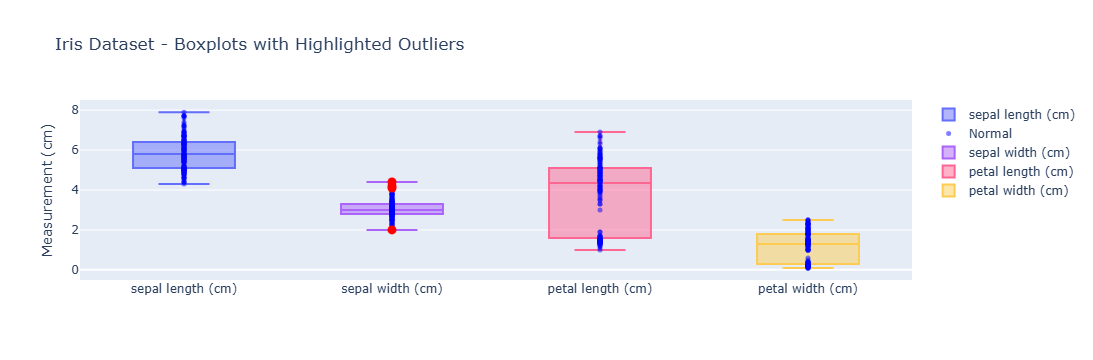

In [35]:
# 8. Check for outliers using Box - Plots

import plotly.graph_objects as go
import numpy as np

fig = go.Figure()

for col in iris_clust_df.columns:
    Q1 = iris_clust_df[col].quantile(0.25)
    Q3 = iris_clust_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (iris_clust_df[col] < lower) | (iris_clust_df[col] > upper)

    # Boxplot without automatically displayed points
    fig.add_trace(go.Box(
        y=iris_clust_df[col],
        name=col,
        boxpoints=False
    ))

    # Normal observations
    fig.add_trace(go.Scatter(
        x=np.full((~outliers).sum(), col),
        y=iris_clust_df.loc[~outliers, col],
        mode="markers",
        marker=dict(color="blue", size=5, opacity=0.5),
        name="Normal",
        showlegend=(col == iris_clust_df.columns[0])
    ))

    # Outliers
    fig.add_trace(go.Scatter(
        x=np.full(outliers.sum(), col),
        y=iris_clust_df.loc[outliers, col],
        mode="markers",
        marker=dict(color="red", size=9),
        name="Outlier",
        showlegend=(col == iris_clust_df.columns[0])
    ))

fig.update_layout(
    title="Iris Dataset - Boxplots with Highlighted Outliers",
    yaxis_title="Measurement (cm)"
)

fig.show()


**How to interpret the chart:** 

- 🔵 Blue dots: Observations within the IQR-based limits.
- 🔴 Red dots: Potential outliers beyond those limits.
- Boxes: Show the median and interquartile range.

***Outlier Detection and Analysis***

The boxplots illustrate the distribution of the four numerical features in the Iris dataset: sepal length, sepal width, petal length, and petal width. Using the 1.5 × Interquartile Range (IQR) method, several potential outliers were identified in sepal width, while no significant outliers were detected in the remaining features. Although K-Means clustering is sensitive to outliers because extreme values can influence cluster centroids and distort Euclidean distance calculations, these observations will be retained. The Iris dataset contains three different flower species (Setosa, Versicolor, and Virginica), each exhibiting distinct physical characteristics. Therefore, unusual measurements may reflect natural biological variation rather than data quality issues. Removing these observations could result in information loss and potentially alter the underlying clustering structure. Consequently, all 150 observations will be retained for feature scaling and subsequent K-Means clustering analysis.

**Summary Results:**

Each box represents one feature, measured in centimeters.
Feature	Observation

Sepal length: No apparent outliers. Measurements range approximately from 4.3 to 7.9 cm.
Sepal width:	Several red points indicate potential outliers, including unusually narrow and wide sepals.
Petal length: No apparent outliers, but the measurements have a wide distribution.
Petal width:	No apparent outliers.

The chart elements mean:
- Colored box: Middle 50% of the measurements.
- Line inside the box: Median.
- Whiskers: Most extreme values within 1.5 × IQR of the box.
- Blue dots: Individual observations within the outlier limits.
- Red dots: Potential outliers outside those limits.

In [38]:
#######Feature Scaling 

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    MaxAbsScaler,
    Normalizer
)


**Feature Scaling**

For the Iris dataset, we will apply Z-score standardization (StandardScaler) because the four features sepal length, sepal width, petal length, and petal width have different ranges and variability. Since K-Means clustering relies on Euclidean distance, scaling ensures that features with larger numerical variation do not disproportionately influence the clustering results. StandardScaler transforms each feature to have a mean of 0 and a standard deviation of 1, allowing all four measurements to contribute on a comparable scale.

In [39]:
# Apply each scaling method to the Iris dataset

X_standard = StandardScaler().fit_transform(iris_clust_df)


In [44]:
X_standard

numpy.ndarray

In [47]:
import pandas as pd

# Convert scaled NumPy array to DataFrame
X_scaled_df = pd.DataFrame(
    X_standard,
    columns=iris_clust_df.columns,
    index=iris_clust_df.index
)

# Display the first 5 rows
display(X_scaled_df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


In [48]:
# Check mean and standard deviation
print("Mean:")
print(X_scaled_df.mean())

print("\nStandard Deviation:")
print(X_scaled_df.std(ddof=0))

Mean:
sepal length (cm)   -1.468455e-15
sepal width (cm)    -1.823726e-15
petal length (cm)   -1.610564e-15
petal width (cm)    -9.473903e-16
dtype: float64

Standard Deviation:
sepal length (cm)    1.0
sepal width (cm)     1.0
petal length (cm)    1.0
petal width (cm)     1.0
dtype: float64


***Summary of Results***

After applying Z-score standardization, each of the four Iris features has a mean essentially equal to zero and a standard deviation of one, which confirms that the measurements were standardized correctly. Small nonzero mean values are due to floating-point precision, not a scaling error. As a result, all four measurements contribute comparably to Euclidean distance calculations in K-Means.

In [51]:
##Determining the Optimal Number of Clusters — Elbow Method and Silhouette Score

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt


***Determining the Optimal Number of Clusters — Elbow Method and Silhouette Score***

For the Iris dataset, we will use both the Elbow Method and Silhouette Score to determine an appropriate number of clusters (K) for K-Means clustering. The Elbow Method evaluates the Within-Cluster Sum of Squares (WCSS), also called inertia, to identify the point where adding more clusters provides diminishing improvements. The Silhouette Score measures how closely observations are grouped within their clusters and how well those clusters are separated from one another. By comparing both methods, we can make a more informed decision about the optimal number of clusters rather than relying on a single evaluation metric.

We'll test K = 2 through 10 for both methods. We exclude K = 1 because the Silhouette Score requires at least two clusters.

C:\Users\husse\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\husse\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\husse\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\husse\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

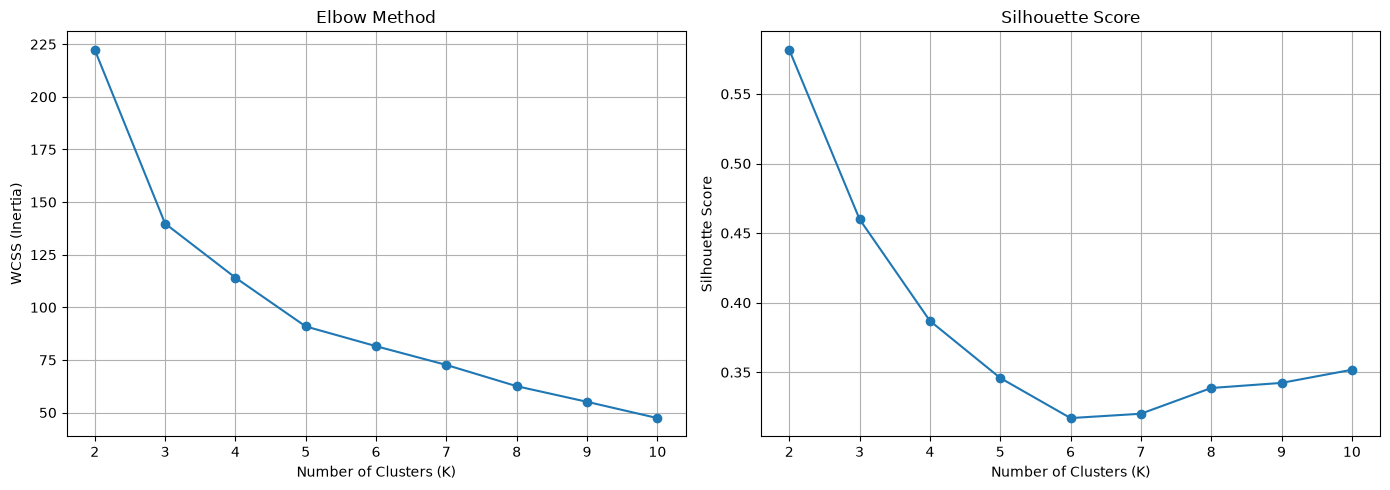

In [54]:
# Store evaluation results
wcss = []
silhouette_scores = []

# Test different numbers of clusters
K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit K-Means to standardized Iris data
    labels = kmeans.fit_predict(X_standard)

    # Calculate WCSS
    wcss.append(kmeans.inertia_)

    # Calculate Silhouette Score
    silhouette_scores.append(
        silhouette_score(X_standard, labels)
    )

# Create two graphs side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method
axes[0].plot(K_range, wcss, marker='o')
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("WCSS (Inertia)")
axes[0].set_xticks(list(K_range))
axes[0].grid(True)

# Silhouette Score
axes[1].plot(K_range, silhouette_scores, marker='o')
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(K_range))
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Results Summary**

The Elbow Method and Silhouette Score were applied to evaluate the optimal number of clusters for the standardized Iris dataset. The Elbow Method suggests that K = 3 is a reasonable candidate, as the reduction in within-cluster variation begins to slow after this point. However, the Silhouette Score reaches its highest value of approximately 0.58 at K = 2, indicating better cluster cohesion and separation with two clusters. Since the methods suggest different solutions, we will evaluate both K = 2 and K = 3 to determine how effectively K-Means identifies the underlying structure of the Iris dataset.

In [55]:
########Compare K-Means Clustering (K = 2 vs. K = 3) Using Plotly

import pandas as pd
import plotly.express as px

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

**Compare K-Means Clustering (K = 2 vs. K = 3) Using Plotly**

We'll compare K-means with two and three clusters using the standardized Iris features. We'll visualize results two ways: PCA, which summarizes all four measurements into two components, and a direct plot of petal length versus petal width. PCA shows overall structure, while the petal plot uses familiar measurements. In all cases, the clustering itself is trained on all four standardized features we're only changing how we view it, not how we train it. This helps us judge whether K equals 2 or K equals 3 gives clearer, more meaningful groups before we compare them to the known species.

C:\Users\husse\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\husse\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,K,WCSS,Silhouette Score
0,2,222.361705,0.581750
1,3,139.820496,0.459948


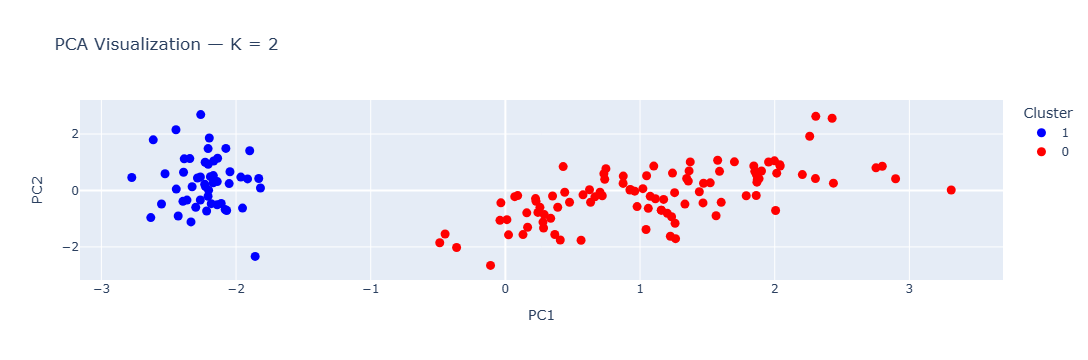

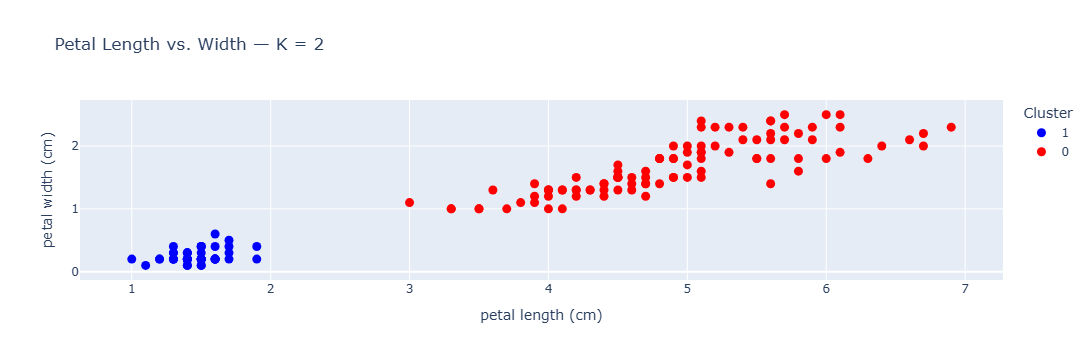

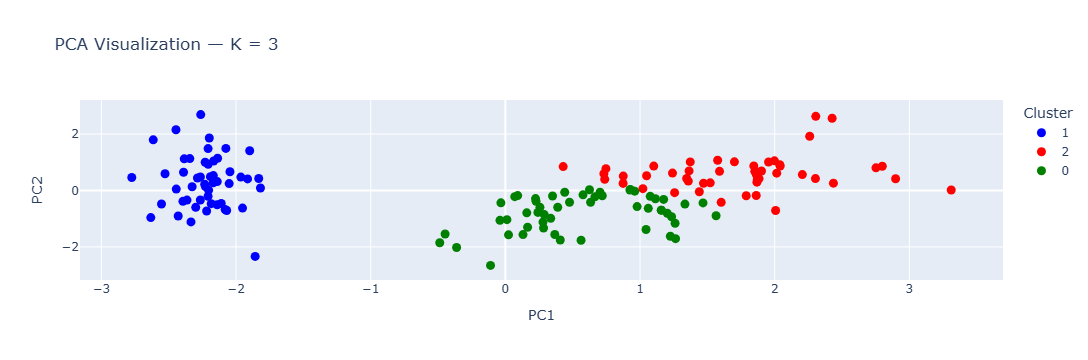

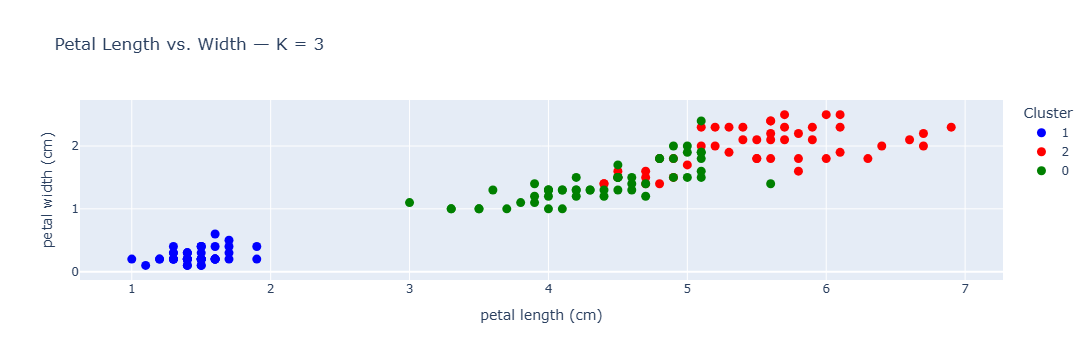

In [58]:
# 1. Fit K-Means for K = 2 and K = 3

results = []
cluster_labels = {}

for k in [2, 3]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_standard)
    cluster_labels[k] = labels

    results.append({
        "K": k,
        "WCSS": model.inertia_,
        "Silhouette Score": silhouette_score(X_standard, labels)
    })

display(pd.DataFrame(results))


# 2. Apply PCA for visualization only

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standard)

# Create visualization DataFrame
df_plot = iris_clust_df[
    ["petal length (cm)", "petal width (cm)"]
].copy()

df_plot["PC1"] = X_pca[:, 0]
df_plot["PC2"] = X_pca[:, 1]

df_plot["Cluster_K2"] = cluster_labels[2].astype(str)
df_plot["Cluster_K3"] = cluster_labels[3].astype(str)


# 3. Plot PCA and original features for each K

for k in [2, 3]:

    cluster_col = f"Cluster_K{k}"

    colors = (
        ["blue", "red"]
        if k == 2
        else ["blue", "red", "green"]
    )

    # PCA visualization
    fig_pca = px.scatter(
        df_plot,
        x="PC1",
        y="PC2",
        color=cluster_col,
        title=f"PCA Visualization — K = {k}",
        color_discrete_sequence=colors,
        labels={cluster_col: "Cluster"}
    )

    fig_pca.update_traces(marker=dict(size=9))
    fig_pca.show()

    # Original features visualization
    fig_original = px.scatter(
        df_plot,
        x="petal length (cm)",
        y="petal width (cm)",
        color=cluster_col,
        title=f"Petal Length vs. Width — K = {k}",
        color_discrete_sequence=colors,
        labels={cluster_col: "Cluster"}
    )

    fig_original.update_traces(marker=dict(size=9))
    fig_original.show()

***Result Summary:***

I compared K-means with K equals two and K equals three using PCA plots and petal length-versus-width plots. With K equals two, one cluster largely captures Setosa while the other combines Versicolor and Virginica, yielding clearer separation and a higher silhouette around 0.58. With K equals three, the model separates an additional group, but Versicolor and Virginica overlap, reducing silhouette to about 0.46. PCA summarizes all four features, while the petal plots show the original dimensions. Overall, K equals two separates better, while K equals three may better reflect the three species. We'll validate this against the true labels next.

In [59]:
##Evaluating K-Means Clustering Performance
import pandas as pd
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

**Evaluating K-Means Clustering Performance**

we will evaluate how well our K-Means models (K = 2 and K = 3) identify the three actual Iris species: Setosa, Versicolor, and Virginica. We will use cross-tabulation to compare predicted cluster assignments with actual species labels, the Adjusted Rand Index (ARI) to measure clustering agreement while accounting for chance, and Normalized Mutual Information (NMI) to measure how much information the clusters share with the true species classifications. These metrics will help us determine whether K = 2 or K = 3 better represents the actual species, even though K = 2 achieved a higher Silhouette Score.

We will use three evaluation methods:
1. Adjusted Rand Index (ARI): Measures agreement between predicted clusters and actual species labels, adjusted for chance. A score of 1 indicates perfect agreement, while 0 indicates chance-level agreement.
2. Normalized Mutual Information (NMI): Measures how much information the cluster assignments share with the actual species labels. Scores range from 0 to 1, with higher values indicating stronger agreement.
3. Cross-tabulation: Displays the number of flowers from each species assigned to each cluster, helping us identify which species are grouped together.
These methods will help us determine whether K = 3 better represents the three Iris species, even though K = 2 achieved a higher Silhouette Score.

In [63]:
# Actual Iris species
# Assumes df contains the species names in a column called "species"
y_true = iris_df["target"]

# Store evaluation results
evaluation_results = []

# Compare K = 2 and K = 3
for k in [2, 3]:

    # Retrieve predicted cluster assignments
    y_pred = cluster_labels[k]

    # Calculate evaluation metrics
    ari = adjusted_rand_score(y_true, y_pred)
    nmi = normalized_mutual_info_score(y_true, y_pred)

    evaluation_results.append({
        "K": k,
        "Adjusted Rand Index": ari,
        "Normalized Mutual Information": nmi
    })

    # Compare actual species with predicted clusters
    print(f"\nCross-tabulation for K = {k}")

    cross_tab = pd.crosstab(
        y_true,
        y_pred,
        rownames=["Actual Species"],
        colnames=["Predicted Cluster"]
    )

    display(cross_tab)

# Display comparison table
evaluation_df = pd.DataFrame(evaluation_results)

print("\nModel Evaluation Comparison")
display(evaluation_df)


Cross-tabulation for K = 2


Predicted Cluster,0,1
Actual Species,,
0,0,50
1,50,0
2,50,0



Cross-tabulation for K = 3


Predicted Cluster,0,1,2
Actual Species,,,
0,0,50,0
1,39,0,11
2,14,0,36



Model Evaluation Comparison


,K,Adjusted Rand Index,Normalized Mutual Information
0,2,0.568116,0.733680
1,3,0.620135,0.659487


***Result Interpretation & Conclusion:***

The K-Means clustering analysis demonstrated that the Iris dataset contains meaningful patterns that allow the three flower species to be distinguished based on their physical measurements. With K = 2, the model successfully separated all 50 Setosa flowers but grouped Versicolor and Virginica together, achieving a higher Silhouette Score (0.58) and NMI (0.7337). With K = 3, the model successfully isolated Setosa and partially distinguished Versicolor from Virginica, achieving a higher Adjusted Rand Index (0.6201) and an overall majority-mapped agreement of 83.3% (125 out of 150 flowers). Although K = 2 produced better-separated clusters, K = 3 better aligned with the three known species according to ARI. Therefore, K = 3 was selected as the preferred model for identifying the three Iris species, while acknowledging the overlap between Versicolor and Virginica.


In [64]:
##Train-Test Split (80/20) and Predicting New Observations

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)

***Train-Test Split (80/20) and Predicting New Observations***

In this final step, we will evaluate how our K-Means clustering model performs on unseen Iris observations. The dataset will be divided into 80% training data (120 flowers) and 20% testing data (30 flowers). We will apply Z-score standardization using only the training data to prevent data leakage, then train K-Means with K = 3. The trained model will assign the unseen test observations to the nearest cluster centroids. Finally, we will compare the predicted cluster assignments against the actual Iris species using the Adjusted Rand Index (ARI), Normalized Mutual Information (NMI), and cross-tabulation to assess how well the model generalizes to new observations.

In [67]:
# 1. Define features and target
X = iris_clust_df.copy()
y = iris_df["target"]

# 2. Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# 3. Standardize features
# Fit scaler ONLY on training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaler to test data
X_test_scaled = scaler.transform(X_test)

# 4. Train K-Means with K = 3
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

train_clusters = kmeans.fit_predict(X_train_scaled)

# 5. Predict clusters for unseen test data
test_clusters = kmeans.predict(X_test_scaled)

# 6. Evaluate clustering performance
ari = adjusted_rand_score(y_test, test_clusters)
nmi = normalized_mutual_info_score(y_test, test_clusters)
silhouette = silhouette_score(
    X_test_scaled,
    test_clusters
)

print("Test Adjusted Rand Index:", round(ari, 4))
print("Test Normalized Mutual Information:", round(nmi, 4))
print("Test Silhouette Score:", round(silhouette, 4))

# 7. Compare actual species with predicted clusters
comparison = pd.crosstab(
    y_test,
    test_clusters,
    rownames=["Actual Species"],
    colnames=["Predicted Cluster"]
)

display(comparison)

Training Data: (120, 4)
Testing Data: (30, 4)
Test Adjusted Rand Index: 0.5489
Test Normalized Mutual Information: 0.6293
Test Silhouette Score: 0.394


C:\Users\husse\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Predicted Cluster,0,1,2
Actual Species,,,
0,0,10,0
1,3,0,7
2,7,0,3


**Train-Test Evaluation and Final Conclusion**

The Iris dataset was divided into 80% training data (120 observations) and 20% testing data (30 observations) to evaluate how K-Means clustering performs on unseen observations. StandardScaler was fitted exclusively on the training data to prevent data leakage, and K-Means was trained using three clusters. The model achieved an Adjusted Rand Index of 0.5489, a Normalized Mutual Information score of 0.6293, and a Silhouette Score of 0.3940 on the test dataset. Cross-tabulation showed that all 10 Setosa flowers were grouped correctly into a distinct cluster, while Versicolor and Virginica exhibited some overlap. After matching clusters to their majority species, 24 of the 30 test observations (80%) agreed with their actual species labels. Overall, the results demonstrate that K-Means can identify meaningful patterns in the Iris dataset, particularly for Setosa, although distinguishing Versicolor from Virginica remains challenging.